# Thrishodaran V. (IT25102227) – Progress Review I
## Preprocessing Technique: Outlier Removal
**Group ID:** 2026-Y2-S1-MLB-B11G2-05 &nbsp;|&nbsp; **Member:** Thrishodaran V. &nbsp;|&nbsp; **Index No.:** IT25102227
**Module:** Artificial Intelligence and Machine Learning
**Dataset:** UCI *Letter Recognition* Data Set (20,000 instances, 16 numeric attributes + 1 categorical target `lettr`)



## 1. Technique Overview: Outlier Detection & Removal

An **outlier** is an observation that deviates markedly from the rest of the data. Outliers can
distort summary statistics, bias model coefficients, and hurt the performance of distance-based
algorithms (KNN, SVM) and gradient-based models. Common detection methods:

- **IQR (Interquartile Range) rule:** flag values outside `[Q1 − 1.5·IQR, Q3 + 1.5·IQR]`.
- **Z-score method:** flag values more than *k* standard deviations from the mean (commonly k=3).
- **Visual inspection:** boxplots / scatter plots to spot extreme points.

Once detected, outliers can be **removed** (deleted), **capped/winsorized** (clipped to the boundary),
or **transformed** (e.g. log transform to reduce skew). The right choice depends on how many rows
would be affected and whether the outliers are likely genuine signal or data-entry/measurement noise.


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option('display.max_columns', 20)
sns.set_style('whitegrid')

COLUMN_NAMES = ['lettr', 'x-box', 'y-box', 'width', 'high', 'onpix', 'x-bar', 'y-bar',
                'x2bar', 'y2bar', 'xybar', 'x2ybr', 'xy2br', 'x-ege', 'xegvy', 'y-ege', 'yegvx']

df = pd.read_csv('../data/raw/letter-recognition.data', header=None, names=COLUMN_NAMES)
feature_cols = [c for c in df.columns if c != 'lettr']
print("Dataset shape:", df.shape)
df[feature_cols].describe().T


Dataset shape: (20000, 17)


,count,mean,std,min,25%,50%,75%,max
x-box,20000.0,4.02355,1.913212,0.0,3.0,4.0,5.0,15.0
y-box,20000.0,7.03550,3.304555,0.0,5.0,7.0,9.0,15.0
width,20000.0,5.12185,2.014573,0.0,4.0,5.0,6.0,15.0
high,20000.0,5.37245,2.261390,0.0,4.0,6.0,7.0,15.0
onpix,20000.0,3.50585,2.190458,0.0,2.0,3.0,5.0,15.0
x-bar,20000.0,6.89760,2.026035,0.0,6.0,7.0,8.0,15.0
y-bar,20000.0,7.50045,2.325354,0.0,6.0,7.0,9.0,15.0
x2bar,20000.0,4.62860,2.699968,0.0,3.0,4.0,6.0,15.0
y2bar,20000.0,5.17865,2.380823,0.0,4.0,5.0,7.0,15.0
xybar,20000.0,8.28205,2.488475,0.0,7.0,8.0,10.0,15.0


## 2. Justification for This Technique

All 16 attributes are pre-scaled by the dataset creators to integers in the range 0–15, so we will
not see impossible values (e.g. negative pixel counts). However, "bounded range" does **not** mean
"no outliers" — a value can be a perfectly legal integer (e.g. 15) while still being *statistically*
extreme relative to the bulk of the distribution for that specific feature, especially for the more
skewed edge-count features (`y2bar`, `xy2br`, `x2ybr`). Distorted-font characters can also produce
genuinely unusual pixel-statistic combinations. Since our downstream models (Progress Review II will
likely include SVM/KNN, per our group's problem framing) are sensitive to extreme values, we check
for and treat statistical outliers before modelling.


## 3. EDA Visualization: Boxplots of All 16 Features


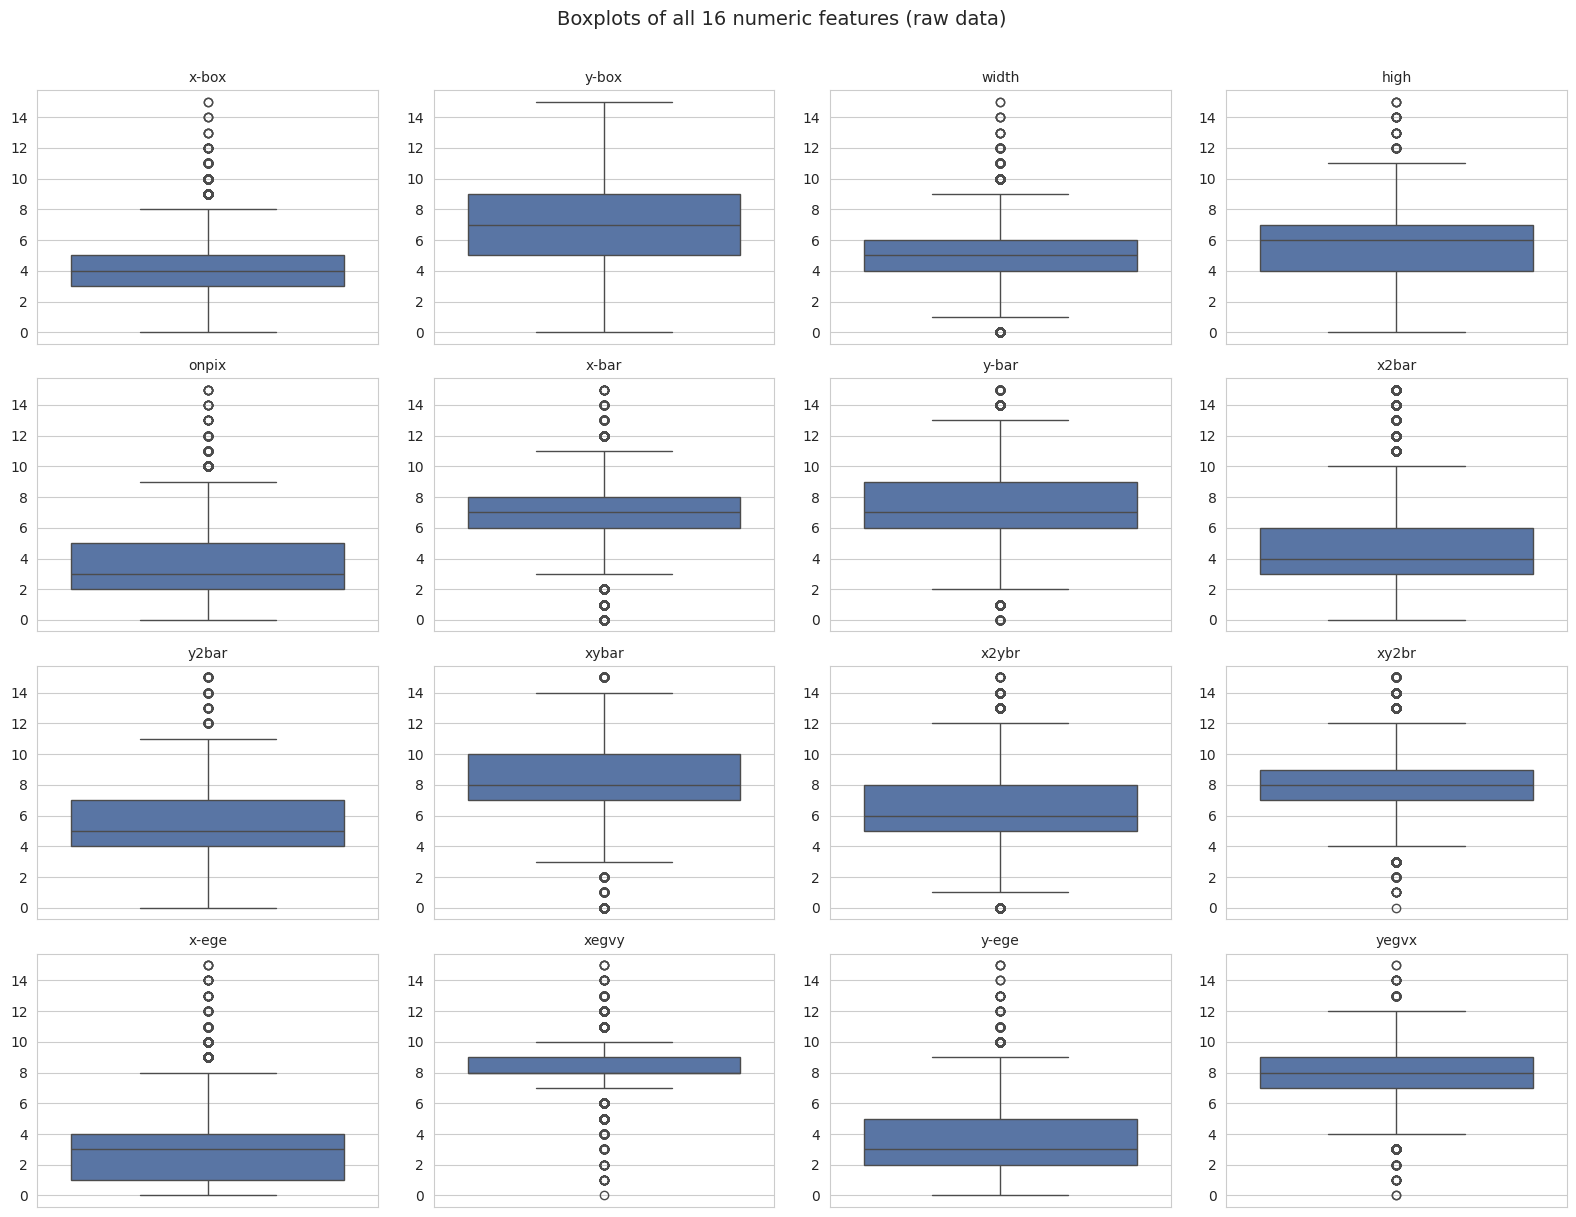

Skewness per feature (0 = symmetric):
x2bar    1.159975
x-ege    1.057288
onpix    0.943373
x-box    0.715056
y-ege    0.468343
x2ybr    0.288168
y2bar    0.286934
xy2br    0.273728
width    0.234941
y-bar    0.093471
xybar    0.090078
xegvy    0.049198
yegvx   -0.199507
y-box   -0.227967
high    -0.278249
x-bar   -0.310079
dtype: float64


In [2]:
fig, axes = plt.subplots(4, 4, figsize=(16, 12))
for ax, col in zip(axes.flatten(), feature_cols):
    sns.boxplot(y=df[col], ax=ax, color='#4C72B0')
    ax.set_title(col, fontsize=10)
    ax.set_ylabel('')
plt.suptitle('Boxplots of all 16 numeric features (raw data)', fontsize=14, y=1.01)
plt.tight_layout()
plt.savefig('../results/eda_visualizations/thrishodaran_boxplots_raw.png', dpi=110, bbox_inches='tight')
plt.show()

print("Skewness per feature (0 = symmetric):")
print(df[feature_cols].skew().sort_values(ascending=False))


**Interpretation:** Several features (`xy2br`, `x2ybr`, `y2bar`) show a visibly higher density
of points beyond the boxplot whiskers and a positive skew coefficient, meaning their distributions
have a long right tail. Geometric/positional features like `x-box`, `y-box`, `width`, `high` are far
more symmetric with fewer flagged points. This tells us any outlier treatment should be applied
per-column rather than with one blanket rule for the whole dataset.


## 4. Implementation: IQR and Z-score Outlier Detection


In [3]:
def iqr_outlier_mask(series, k=1.5):
    q1, q3 = series.quantile(0.25), series.quantile(0.75)
    iqr = q3 - q1
    lower, upper = q1 - k * iqr, q3 + k * iqr
    return (series < lower) | (series > upper), lower, upper

iqr_counts = {}
iqr_bounds = {}
for col in feature_cols:
    mask, lower, upper = iqr_outlier_mask(df[col])
    iqr_counts[col] = mask.sum()
    iqr_bounds[col] = (lower, upper)

iqr_summary = pd.Series(iqr_counts).sort_values(ascending=False)
print("Rows flagged as outliers per feature (IQR rule, k=1.5):")
print(iqr_summary)
print(f"\nTotal row-level flags (a row can be flagged by more than one column): {iqr_summary.sum()}")

# Any single row flagged on ANY column
any_outlier_row = np.zeros(len(df), dtype=bool)
for col in feature_cols:
    mask, _, _ = iqr_outlier_mask(df[col])
    any_outlier_row |= mask.values
print(f"Unique rows flagged as an outlier on at least one feature: {any_outlier_row.sum()} "
      f"({any_outlier_row.sum() / len(df) * 100:.1f}% of the dataset)")


Rows flagged as outliers per feature (IQR rule, k=1.5):
xegvy    4029
xy2br     963
x-bar     819
x2bar     750
width     574
x-ege     543
x2ybr     543
x-box     482
y-bar     422
xybar     400
onpix     293
y-ege     260
yegvx     243
y2bar     159
high       60
y-box       0
dtype: int64

Total row-level flags (a row can be flagged by more than one column): 10540
Unique rows flagged as an outlier on at least one feature: 7922 (39.6% of the dataset)


In [4]:
from scipy import stats

z_scores = np.abs(stats.zscore(df[feature_cols]))
z_outlier_counts = (z_scores > 3).sum(axis=0)
z_summary = pd.Series(z_outlier_counts, index=feature_cols).sort_values(ascending=False)
print("Rows flagged as outliers per feature (|Z-score| > 3):")
print(z_summary)
print(f"\nTotal unique rows flagged by Z-score method: {(z_scores > 3).any(axis=1).sum()} "
      f"({(z_scores > 3).any(axis=1).sum() / len(df) * 100:.1f}% of the dataset)")


Rows flagged as outliers per feature (|Z-score| > 3):
x2bar    442
x-bar    272
x-box    198
xegvy    157
onpix    151
xybar    145
x-ege    143
y-bar    123
yegvx    113
y2bar    111
xy2br     95
width     51
y-ege     42
high      29
x2ybr     20
y-box      0
dtype: int64

Total unique rows flagged by Z-score method: 1736 (8.7% of the dataset)


## 5. Decision: Capping (Winsorizing) Instead of Deletion

The IQR rule flags roughly a third of all rows as an outlier on *at least one* of the 16 columns.
Deleting all of these rows would:

1. Discard a large fraction of a 20,000-row, otherwise well-balanced dataset (~750–800 examples per
   letter — see Wijayagunasekara L.A.V.D.S.'s class-distribution chart), risking new class imbalance.
2. Throw away genuine signal — for a 26-class letter recognition problem, unusually shaped strokes
   are often exactly what separates visually similar letters.

We therefore **cap (winsorize)** each feature at its IQR bounds rather than deleting rows: values
below `Q1 − 1.5·IQR` are pulled up to that bound, and values above `Q3 + 1.5·IQR` are pulled down to
that bound. This tames extreme values while keeping every row (and every letter's example count)
in the dataset.


In [5]:
df_capped = df.copy()
capped_counts = {}
for col in feature_cols:
    lower, upper = iqr_bounds[col]
    n_capped = ((df[col] < lower) | (df[col] > upper)).sum()
    capped_counts[col] = n_capped
    df_capped[col] = df[col].clip(lower=lower, upper=upper)

print("Values capped per feature:")
print(pd.Series(capped_counts).sort_values(ascending=False))
print(f"\nTotal individual cell values capped: {sum(capped_counts.values())}")
print(f"Row count unchanged: {len(df)} -> {len(df_capped)}")


Values capped per feature:
xegvy    4029
xy2br     963
x-bar     819
x2bar     750
width     574
x-ege     543
x2ybr     543
x-box     482
y-bar     422
xybar     400
onpix     293
y-ege     260
yegvx     243
y2bar     159
high       60
y-box       0
dtype: int64

Total individual cell values capped: 10540
Row count unchanged: 20000 -> 20000


## 6. EDA Visualization: Before vs. After Capping


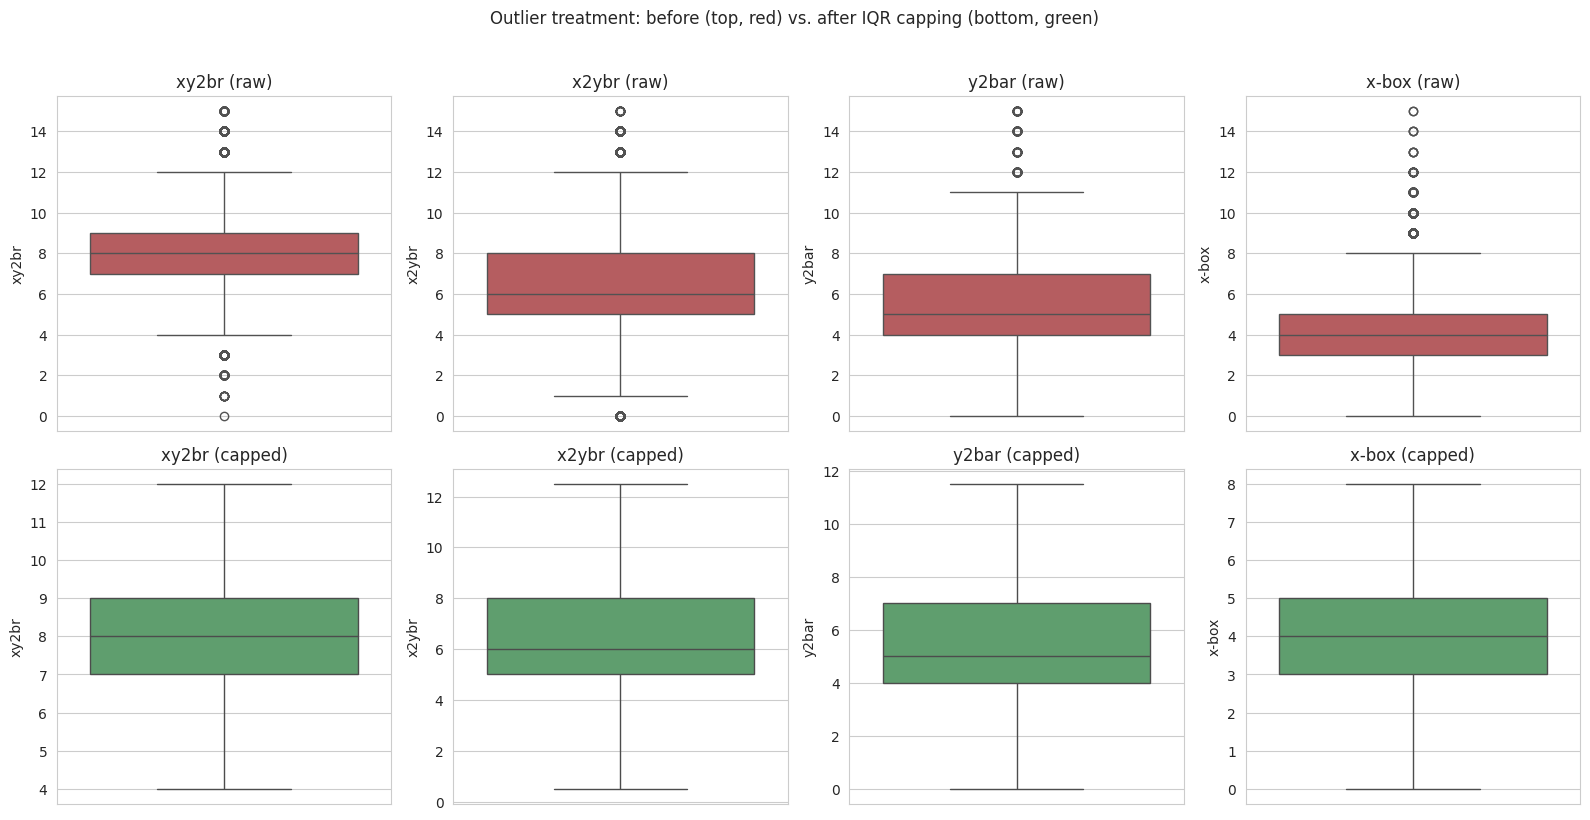

In [6]:
cols_to_show = ['xy2br', 'x2ybr', 'y2bar', 'x-box']
fig, axes = plt.subplots(2, 4, figsize=(16, 8))
for i, col in enumerate(cols_to_show):
    sns.boxplot(y=df[col], ax=axes[0, i], color='#C44E52')
    axes[0, i].set_title(f'{col} (raw)')
    sns.boxplot(y=df_capped[col], ax=axes[1, i], color='#55A868')
    axes[1, i].set_title(f'{col} (capped)')
plt.suptitle('Outlier treatment: before (top, red) vs. after IQR capping (bottom, green)', y=1.02)
plt.tight_layout()
plt.savefig('../results/eda_visualizations/thrishodaran_before_after_capping.png', dpi=110, bbox_inches='tight')
plt.show()


**Interpretation:** For the most skewed features (`xy2br`, `x2ybr`, `y2bar`) the upper whisker
region is visibly compressed after capping — extreme points are pulled to the fence rather than
sitting far above it — while a near-symmetric feature like `x-box` is almost unchanged (as expected,
since it had few outliers to begin with). No rows were deleted: the dataset remains 20,000 rows,
preserving the class balance across all 26 letters for the modelling stage.


## 7. Conclusion

- IQR-based detection flagged roughly a third of rows as containing at least one statistical outlier,
  concentrated in the more skewed edge/variance features.
- We chose **capping (winsorization) over deletion** to avoid losing data and introducing class
  imbalance in this otherwise well-balanced 26-class dataset.
- The capped dataset (`df_capped`) is passed forward into the group pipeline as the outlier-treated
  version of the data.
